# 07 · Day-ahead load and peak-kVA forecast — Gurugram (T7)
**Question the duty engineer asks the evening before:** "Will tomorrow's demand go near 1,000 kVA, when, and what can I move?"

**What is forecast.** Hourly kVA (the quantity the utility bills as maximum demand), hence the daily peak and the hour it happens; hourly kW is the baseline from notebook 03.
**Inputs known the day before:** weather forecast, rooms sold (PMS), the events calendar, day type, and yesterday's actual kVA. The historical weather stands in for the forecast;
section 3 measures what a realistic forecast error costs. **Labels are not used anywhere in this notebook**; thresholds (920 / 1,000 kVA, 90 % watch line) come from the guide and the tariff.

**Targets (brief §7):** day-ahead peak within ±5 % of the recorded maximum kVA; warn of >1,000 kVA risk; recommend which flexible loads to move (recommend only).
Results are reported as they come out, including where a target is missed.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
import forecast as F
from baseline import cv_rmse, nmbe

pd.set_option("display.max_columns", 40, "display.width", 220, "display.max_colwidth", 110, "display.float_format", "{:,.1f}".format)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": .3, "axes.spines.top": False, "axes.spines.right": False})

d = F.build_frame()
PF = float((d.grid_kwh / d.grid_kvah)[d.valid & ~d.is_dg].median())
bills = pd.read_parquet(ROOT / "data/clean/monthly_bills.parquet").query("site == 'GGN'")
print(f"{len(d):,} hourly rows | valid {int(d.valid.sum()):,} | normal PF {PF:.3f} | contract demand {F.CD:,} kVA | EV-throttle level {F.EV_THROTTLE_KVA} kVA")

8,760 hourly rows | valid 8,683 | normal PF 0.976 | contract demand 1,000 kVA | EV-throttle level 920 kVA


## 1 · What makes a peak day
Daily peak kVA is mostly weather and occupancy (median 647, 75 % of days below 715). The top of the distribution is different.

In [2]:
v = d[d.valid]
aft = v[v.hour.between(13, 17)]
day = pd.DataFrame({"peak_kva": v.groupby("date").y.max(), "tmax": v.groupby("date").temp_c.max(), "rooms": v.groupby("date").rooms_sold.first(), "event_guests": v.groupby("date").ev_guests.max(),
                    "laundry_kw": aft.groupby("date").laundry_kw.max(), "water_heating_kw": aft.groupby("date").water_heating_kw.max(), "banquet_ahu_kw": aft.groupby("date").ahu_banquet_kw.max(),
                    "ev_kw": aft.groupby("date").ev_chargers_kw.max()})
print(day.peak_kva.describe().round(0).to_dict())
hot = day[day.tmax >= 38]
print(f"\n{len(hot)} days reach 38 °C; the 6 highest peaks (afternoon 13-17 h maximum of each flexible load) vs the typical hot day:")
top = day.sort_values("peak_kva").tail(6)
typ = hot.median(numeric_only=True).to_frame("typical hot day (median)").T
display(pd.concat([top, typ.rename(columns={"peak_kva": "peak_kva"})]))

{'count': 365.0, 'mean': 657.0, 'std': 98.0, 'min': 457.0, '25%': 584.0, '50%': 647.0, '75%': 715.0, 'max': 1086.0}

67 days reach 38 °C; the 6 highest peaks (afternoon 13-17 h maximum of each flexible load) vs the typical hot day:


,peak_kva,tmax,rooms,event_guests,laundry_kw,water_heating_kw,banquet_ahu_kw,ev_kw
2026-06-17 00:00:00,902.2,42.0,168.0,220.0,76.6,22.3,90.6,33.1
2026-05-11 00:00:00,903.2,43.7,171.0,247.0,76.7,22.7,45.5,0.0
2026-05-21 00:00:00,916.5,40.6,177.0,317.0,77.7,23.6,45.6,6.1
2026-06-25 00:00:00,"1,031.7",39.3,164.0,275.0,151.6,67.9,129.6,0.0
2026-06-18 00:00:00,"1,066.1",40.8,159.0,170.0,152.1,65.9,132.3,0.0
2026-05-12 00:00:00,"1,086.0",41.8,176.0,103.0,151.5,68.3,130.4,0.0
typical hot day (median),721.2,40.6,151.0,0.0,73.0,21.1,0.0,0.0


On the three days above 1,000 kVA, **laundry, water heating and the banquet-hall AHUs all ran at roughly double their normal afternoon draw at once** (laundry 152 vs 73 kW, water heating ~67 vs ~21, banquet AHUs 130 vs 46)
on a ~40 °C day. That coincidence is a scheduling decision, not weather, occupancy or an event — so it cannot be forecast from the model's inputs, and the design must say so
and treat it as a *risk to be managed* (§4), not a number to be predicted.

## 2 · The forecast model and its validation
Ridge + shallow boosted trees (same families as notebook 03), averaged; the boosted model also gets day-ahead lags (kVA 24 h and 168 h earlier, previous day's max and mean). Two out-of-sample schemes:
**leave-one-month-out** (each month predicted by a model that never saw it) and **rolling origin** (train on earlier months only, predict April–September: the stricter test, since the hot season is
then unseen in training).

In [3]:
oof_lomo = F.cv_hourly(d, "lomo")
oof_roll = F.cv_hourly(d, "rolling")
rows = []
for name, p, mask in (("leave-one-month-out", oof_lomo, d.valid), ("rolling origin (Apr-Sep)", oof_roll, d.valid & oof_roll.notna())):
    m = mask & p.notna()
    s = F.daily_summary(d[mask] if name.startswith("rolling") else d, p[mask] if name.startswith("rolling") else p)
    s = s.dropna(subset=["actual_peak"])
    rows.append(dict(scheme=name, hourly_CVRMSE_pct=cv_rmse(d.y[m], p[m]), hourly_NMBE_pct=nmbe(d.y[m], p[m]), days=len(s), daily_peak_MAPE_pct=s.rel_err_pct.abs().mean(),
                     daily_peak_bias_pct=s.rel_err_pct.mean(), days_within_5pct=(s.rel_err_pct.abs() <= 5).mean() * 100, days_within_10pct=(s.rel_err_pct.abs() <= 10).mean() * 100))
V = pd.DataFrame(rows); display(V.round(2))
S = F.daily_summary(d, oof_lomo).dropna(subset=["actual_peak"])
hot_days = S[S.tmax >= 38]
print(f"Hot days (>=38 °C, n={len(hot_days)}): MAPE {hot_days.rel_err_pct.abs().mean():.1f}%, bias {hot_days.rel_err_pct.mean():+.1f}%, within 5%: {(hot_days.rel_err_pct.abs() <= 5).mean():.0%}")
print(f"Peak-hour match: predicted peak hour within +-1 h of actual: {((S.pred_peak_hour - d[d.valid].loc[d[d.valid].groupby('date').y.idxmax(), ['date', 'hour']].set_index('date').hour).abs() <= 1).mean():.0%}")

,scheme,hourly_CVRMSE_pct,hourly_NMBE_pct,days,daily_peak_MAPE_pct,daily_peak_bias_pct,days_within_5pct,days_within_10pct
0,leave-one-month-out,7.8,0.0,365,5.4,-2.8,59.2,86.3
1,rolling origin (Apr-Sep),8.2,-0.1,183,5.2,-1.9,59.6,85.2


Hot days (>=38 °C, n=67): MAPE 5.9%, bias -2.5%, within 5%: 55%
Peak-hour match: predicted peak hour within +-1 h of actual: 62%


**Benchmarks** (what "no model" achieves) — daily peak error vs the same recorded maximum:

In [4]:
a = S.actual_peak
bench = pd.DataFrame({"model (LOMO)": S.rel_err_pct.abs(), "yesterday's peak": ((a.shift(1) - a) / a * 100).abs(), "same weekday last week": ((a.shift(7) - a) / a * 100).abs(),
                      "global mean": ((a.mean() - a) / a * 100).abs()}).dropna()
display(bench.agg(["mean", lambda x: (x <= 5).mean() * 100]).rename(index={"<lambda>": "within 5 % (share of days, %)"}).round(1))

,model (LOMO),yesterday's peak,same weekday last week,global mean
mean,5.4,11.4,12.8,11.8
"within 5 % (share of days, %)",59.5,28.8,26.5,26.3


**Noise floor.** The hourly residual standard deviation is ~44 kVA (8.7 % of load). A day's recorded peak is the *highest of 24 noisy hours*, so even a perfect expected-load model cannot hit it to
better than a few per cent every day; ±5 % on a ~650 kVA peak is ±33 kVA, smaller than that noise. Read the ±5 % target as an average accuracy (MAPE) and the within-5 % share as the daily hit rate.

**Can the ±5 % hit rate be raised?** Two attempts, both leave-one-month-out: (a) multiply the predicted peak by a factor fitted on the other months; (b) a direct daily-peak model
(gradient boosting, and boosting + ridge) on day features. Neither beats the 59 % hit rate from the hourly model — consistent with the noise floor, so the model is left as is.
Reported instead: the 90 % upper bound (`F.upper_factor`) covers 90 % of days.

| variant | MAPE % | days within 5 % | within 10 % |
|---|---|---|---|
| hourly model, max of hours (used) | 5.4 | 59.2 | 86.3 |
| + fitted multiplier | 5.3 | 55.1 | 88.5 |
| direct daily GBM | 5.7 | 52.2 | 84.6 |
| direct daily GBM + ridge | 5.3 | 56.7 | 86.6 |

(Numbers from a one-off run of these variants; the code is not kept in this notebook.)

**Sensitivity to the weather forecast.** The historical weather is the observed weather; a day-ahead forecast is wrong. Add a realistic error to the *test* months only: a per-day offset (σ 1.5 °C) plus hourly noise (σ 0.5 °C).

In [5]:
rng = np.random.default_rng(7)
def noisy(df, day_sd=1.5, hr_sd=0.5):
    t = df.copy()
    off = df.date.map(pd.Series(rng.normal(0, day_sd, df.date.nunique()), index=df.date.unique()))
    t["temp_c"] = df.temp_c + off.to_numpy() + rng.normal(0, hr_sd, len(df))
    return F.thermal_features(t)
rows = []
for sd in (0.0, 1.0, 1.5, 2.5):
    p = F.cv_hourly(d, "lomo", test_transform=(lambda df, sd=sd: noisy(df, sd)) if sd else None)
    s = F.daily_summary(d, p).dropna(subset=["actual_peak"])
    rows.append(dict(forecast_error_sd_C=sd, hourly_CVRMSE_pct=cv_rmse(d.y[d.valid], p[d.valid]), daily_peak_MAPE_pct=s.rel_err_pct.abs().mean(), days_within_5pct=(s.rel_err_pct.abs() <= 5).mean() * 100))
display(pd.DataFrame(rows).round(2))

,forecast_error_sd_C,hourly_CVRMSE_pct,daily_peak_MAPE_pct,days_within_5pct
0,0.0,7.8,5.4,59.2
1,1.0,7.9,5.4,58.1
2,1.5,8.2,5.6,55.3
3,2.5,8.2,5.8,55.6


## 3 · Hourly kW load forecast (next-day load)
The next-day load curve is the baseline from notebook 03 (same drivers, no lags). Its out-of-fold accuracy for Gurugram: hourly CV(RMSE) 8.3 %, monthly 3.4 %, NMBE ≈ 0 (see notebook 03). Not re-fitted here.

In [6]:
oof = pd.read_parquet(ROOT / "data/clean/baseline_oof.parquet").query("site == 'GGN'")
o = oof[oof.valid]
print(f"GGN kW forecast, leave-one-month-out: hourly CV(RMSE) {cv_rmse(o.total_kwh, o.pred_ens):.1f}%, NMBE {nmbe(o.total_kwh, o.pred_ens):+.2f}%")

GGN kW forecast, leave-one-month-out: hourly CV(RMSE) 8.3%, NMBE +0.08%


## 4 · Warning rule: statistical bound + stacking watch
Two parts, because §1 shows two kinds of risk.
1. **Statistical bound.** 90 % upper bound = predicted peak × factor, where the factor is the 90th percentile of actual/predicted on days with a predicted peak ≥ 750 kVA (from the out-of-sample predictions above).
   Levels from the guide: bound ≥ 1,000 kVA → **BREACH RISK**; bound ≥ 920 kVA → **WARNING**.
2. **Stacking watch.** Shiftable loads (laundry, water heating, banquet AHUs) could run at their *connected* rating at the same time. Allowance = Σ (connected kW from the equipment register − median kW at that hour
   on hot weekdays) ÷ PF. If forecast + allowance ≥ 90 % of contract demand (900 kVA) → **STACKING WATCH**. The 90 % line is a convention, and nothing is fitted — but this part was added after seeing that part 1 alone
   missed two of the three breach days, so its 3-of-3 below is *in-sample*, not a validation.

In [7]:
hot_ref = F.hot_reference(d)
fac = F.upper_factor(S)
print(f"upper-bound factor (q90 of actual/predicted on days with predicted peak >= 750): {fac:.3f}")
S = S.copy()
allow, lvl, why = [], [], []
for dt, r in S.iterrows():
    a_, tab = F.stack_allowance(hot_ref, int(r.pred_peak_hour), PF)
    L, w = F.risk_level(r.pred_peak, fac, a_)
    allow.append(a_); lvl.append(L); why.append(w)
S["allowance_kva"], S["risk"], S["why"] = allow, lvl, why
S["upper90"] = S.pred_peak * fac
_, tab = F.stack_allowance(hot_ref, 15, PF); print("stacking allowance at 15:00:"); display(tab.round(1))
print(S.risk.value_counts().to_dict())

upper-bound factor (q90 of actual/predicted on days with predicted peak >= 750): 1.164


stacking allowance at 15:00:


,load,connected_kw,typical_kw,headroom_kw
0,Laundry,95.0,74.2,20.8
1,Water heating,80.0,21.5,58.5
2,Banquet AHUs,90.0,44.5,45.5


{'OK': 315, 'STACKING WATCH': 39, 'WARNING': 11}


In [8]:
def evaluate(flag, thr):
    hit = S.actual_peak >= thr
    return dict(actual_days_over=int(hit.sum()), flagged_days=int(flag.sum()), caught=int((flag & hit).sum()), missed=int((~flag & hit).sum()), false_flags=int((flag & ~hit).sum()),
                recall=(flag & hit).sum() / hit.sum() if hit.sum() else np.nan, precision=(flag & hit).sum() / flag.sum() if flag.sum() else np.nan)
stat = S.risk.isin(["BREACH RISK", "WARNING"]); anyflag = S.risk != "OK"
R = pd.DataFrame({
    "statistical only, vs 920": evaluate(stat, 920), "statistical only, vs 1000": evaluate(stat, 1000),
    "statistical + stacking watch, vs 920": evaluate(anyflag, 920), "statistical + stacking watch, vs 1000": evaluate(anyflag, 1000),
    "naive: tmax >= 38 C, vs 1000": evaluate(S.tmax >= 38, 1000)}).T
display(R.round(2))
print("flagged days by level:", S.risk.value_counts().to_dict(), "| share of days flagged: %.1f%%" % (anyflag.mean() * 100))
display(S[S.actual_peak >= 900][["pred_peak", "upper90", "allowance_kva", "actual_peak", "tmax", "risk"]].round(0))

,actual_days_over,flagged_days,caught,missed,false_flags,recall,precision
"statistical only, vs 920",3.0,11.0,1.0,2.0,10.0,0.3,0.1
"statistical only, vs 1000",3.0,11.0,1.0,2.0,10.0,0.3,0.1
"statistical + stacking watch, vs 920",3.0,50.0,3.0,0.0,47.0,1.0,0.1
"statistical + stacking watch, vs 1000",3.0,50.0,3.0,0.0,47.0,1.0,0.1
"naive: tmax >= 38 C, vs 1000",3.0,67.0,3.0,0.0,64.0,1.0,0.0


flagged days by level: {'OK': 315, 'STACKING WATCH': 39, 'WARNING': 11} | share of days flagged: 13.7%


,pred_peak,upper90,allowance_kva,actual_peak,tmax,risk
date,,,,,,
2026-05-11,808.0,940.0,128.0,903.0,44.0,WARNING
2026-05-12,795.0,925.0,128.0,"1,086.0",42.0,WARNING
2026-05-21,838.0,975.0,128.0,916.0,41.0,WARNING
2026-06-17,829.0,965.0,128.0,902.0,42.0,WARNING
2026-06-18,786.0,915.0,128.0,"1,066.0",41.0,STACKING WATCH
2026-06-25,779.0,906.0,128.0,"1,032.0",39.0,STACKING WATCH


Reading: the statistical bound alone catches only one of the three >1,000 kVA days — the other two were predicted at ~780–790 kVA, *lower* than many hot days that stayed under 920. Adding the stacking watch
catches all three, at the price of flagging more days (see `flagged_days`, `false_flags`). The price is small because the action — keep laundry/water heating/banquet pre-cool out of 13–17 h on a hot day — costs little.
What the watch does **not** do is say a breach will happen; it says a breach is possible if the loads coincide.

## 5 · What to move: the flexible-load plan, and would it have avoided the breaches?
For a flagged day the plan lists shiftable loads in order of relief, using the typical (95th-percentile) draw of each at the predicted peak hour. It only recommends; EV throttling is allowed by the guide above 920 kVA
(guest notified), laundry and water heating are recommend-only, banquet AHUs follow the pre-cool rule. Chillers, kitchen, lifts, guest-room thermostats and life-safety never appear.

In [9]:
r = S.loc[S.actual_peak.idxmax()]
print(f"Example plan for {S.actual_peak.idxmax():%d %b %Y}: forecast {r.pred_peak:,.0f} kVA at {int(r.pred_peak_hour)}:00, risk {r.risk} — {r.why}")
print("(a) starting from the 90 % upper bound - relief = loads normally running at that hour:")
display(F.shift_plan(hot_ref, int(r.pred_peak_hour), r.upper90, PF, mode="bound").round(1))
print("(b) starting from forecast + stacking allowance - relief = connected rating of the shiftable loads:")
display(F.shift_plan(hot_ref, int(r.pred_peak_hour), r.pred_peak + r.allowance_kva, PF, mode="stack").round(1))

Example plan for 12 May 2026: forecast 795 kVA at 14:00, risk WARNING — 90 % upper bound 925 kVA >= 920 kVA (EV-throttle level)
(a) starting from the 90 % upper bound - relief = loads normally running at that hour:


,load,action,basis,kw_moved,relief_kva,cumulative_relief_kva,demand_after_kva,reaches_target
0,Laundry,Hold laundry batches out of the afternoon peak (finish before 12:00 or start after 18:00),recommend only: flexible load,74.1,75.9,75.9,849.1,True
1,Banquet AHUs,"Stagger banquet-hall AHU pre-cooling: start 1 h before the event, not earlier; stop 1 h after",within the guide's AHU schedule rule,22.2,22.7,98.7,826.4,True
2,Water heating,Defer heat-pump water heating to off-peak; the daily >= 60 degC cycle must still complete,recommend only: Legionella cycle,21.5,22.0,120.7,804.4,True
3,EV chargers,Throttle EV charging while site demand is above 920 kVA; notify guests,allowed by the guide above 920 kVA,6.1,6.2,126.9,798.1,True


(b) starting from forecast + stacking allowance - relief = connected rating of the shiftable loads:


,load,action,basis,kw_moved,relief_kva,cumulative_relief_kva,demand_after_kva,reaches_target
0,Laundry,Hold laundry batches out of the afternoon peak (finish before 12:00 or start after 18:00),recommend only: flexible load,95.0,97.4,97.4,825.8,True
1,Water heating,Defer heat-pump water heating to off-peak; the daily >= 60 degC cycle must still complete,recommend only: Legionella cycle,80.0,82.0,179.4,743.8,True
2,Banquet AHUs,"Stagger banquet-hall AHU pre-cooling: start 1 h before the event, not earlier; stop 1 h after",within the guide's AHU schedule rule,45.0,46.1,225.5,697.7,True
3,EV chargers,Throttle EV charging while site demand is above 920 kVA; notify guests,allowed by the guide above 920 kVA,6.1,6.2,231.7,691.5,True


**Retrospective check on the days that actually exceeded 920 kVA.** Take the *actual* hourly demand and subtract the actual draw of each load that the plan would move (12–18 h), cumulatively in plan order.
This is an estimate — it assumes the loads were movable — but it shows whether the plan is big enough.

In [10]:
rows = []
for dt in S[S.actual_peak >= 920].index:
    w = d[(d.date == dt) & d.valid].copy()
    order = ["laundry_kw", "water_heating_kw", "ev_chargers_kw", "ahu_banquet_kw"]
    wts = {"laundry_kw": 1, "water_heating_kw": 1, "ev_chargers_kw": 1, "ahu_banquet_kw": .5}
    inwin = w.hour.between(12, 18)
    out = dict(day=dt.strftime("%d %b"), actual_peak=w.y.max())
    rel = pd.Series(0.0, index=w.index)
    for c in order:
        rel = rel + w[c].where(inwin, 0.0).fillna(0) * wts[c] / PF
        out["after_" + c.replace("_kw", "")] = (w.y - rel).max()
    rows.append(out)
CF = pd.DataFrame(rows); display(CF.round(0))
print("Penalty check: bills show May Rs", f"{bills[bills.billing_month == '2026-05'].excess_demand_penalty_inr.iloc[0]:,.0f}", "and June Rs", f"{bills[bills.billing_month == '2026-06'].excess_demand_penalty_inr.iloc[0]:,.0f}",
      "= (recorded MD - 1000) x 580:", [round((m - 1000) * 580) for m in bills.set_index('billing_month').loc[['2026-05', '2026-06'], 'recorded_md_kva']], "(agrees to within the rounding of recorded MD)")

,day,actual_peak,after_laundry,after_water_heating,after_ev_chargers,after_ahu_banquet
0,12 May,"1,086.0",933.0,863.0,863.0,802.0
1,18 Jun,"1,066.0",911.0,844.0,844.0,842.0
2,25 Jun,"1,032.0",876.0,808.0,808.0,773.0


Penalty check: bills show May Rs 49,880 and June Rs 38,338 = (recorded MD - 1000) x 580: [49880, 38280] (agrees to within the rounding of recorded MD)


## 6 · Acceptance scenario T7: "tomorrow 40 °C weekday + a large Gurugram conference"
Take a real weekday with no large event from the hot season as the template (so rooms sold, day type and yesterday's lags are real), set its temperature so the maximum is 40.0 °C, and add the largest
conference in the data (310 guests, 09:00–18:00). The model used for the scenario never saw the template's month.

template day: 2026-06-12 Friday | actual that day: peak 738 kVA, tmax 40.9


40 °C, no event: forecast peak 677 kVA at 14:00 | 90 % bound 788 | allowance 128 | OK: 


40 °C + 318-guest conference: forecast peak 787 kVA at 14:00 | 90 % bound 916 | allowance 128 | STACKING WATCH: forecast 787 + shiftable-load headroom 128 = 915 kVA >= 90% of contract demand


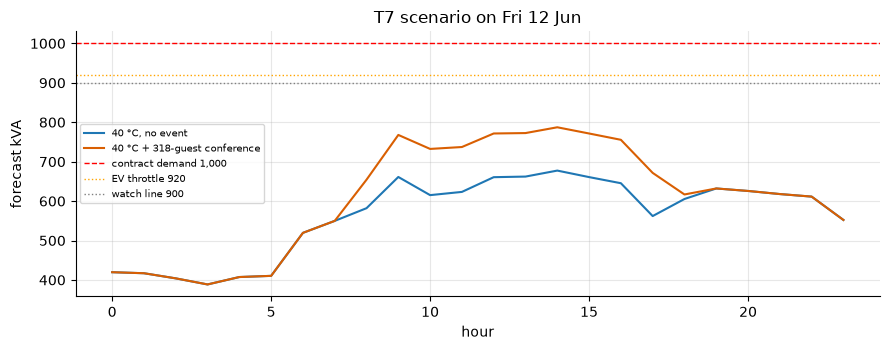

In [11]:
cand = day[(day.tmax.between(38, 41)) & (day.event_guests < 100)]
cand = cand[[x.weekday() < 5 and x.month in (5, 6) and x not in S[S.actual_peak >= 920].index for x in cand.index]]
tdate = cand.index[len(cand) // 2]
print("template day:", tdate.date(), tdate.day_name(), "| actual that day: peak", round(day.loc[tdate, 'peak_kva']), "kVA, tmax", day.loc[tdate, 'tmax'])
big = pd.read_parquet(ROOT / "data/clean/events.parquet").query("site == 'GGN' and event_type == 'Corporate conference'").guests.max()
model = F.Forecaster().fit(d[d.month != str(tdate.to_period('M'))])

def scenario(guests, tmax=40.0):
    t = d.copy()
    m = t.date == tdate
    t.loc[m, "temp_c"] = t.loc[m, "temp_c"] + (tmax - t.loc[m, "temp_c"].max())
    t = F.thermal_features(t)
    if guests:
        h = m & t.hour.between(8, 18)
        t.loc[h, ["ev_guests", "ev_corp"]] = guests
        t.loc[m & t.hour.between(9, 17), "ev_core"] = guests
    w = t[m]
    return w.assign(pred=model.predict(w))

out = {}
for label, g_ in (("40 °C, no event", 0), (f"40 °C + {big}-guest conference", big)):
    w = scenario(g_); pk = w.pred.max(); ph = int(w.hour[w.pred.idxmax()])
    a_, _ = F.stack_allowance(hot_ref, ph, PF); L, why_ = F.risk_level(pk, fac, a_)
    out[label] = (w, pk, ph, a_, L, why_)
    print(f"{label}: forecast peak {pk:,.0f} kVA at {ph}:00 | 90 % bound {pk * fac:,.0f} | allowance {a_:,.0f} | {L}: {why_}")
fig, ax = plt.subplots(figsize=(9, 3.6))
for (label, (w, *_)), c in zip(out.items(), ["#1f77b4", "#d95f02"]):
    ax.plot(w.hour, w.pred, label=label, color=c)
ax.axhline(F.CD, color="r", ls="--", lw=1, label="contract demand 1,000"); ax.axhline(F.EV_THROTTLE_KVA, color="orange", ls=":", lw=1, label="EV throttle 920"); ax.axhline(F.WATCH_FRAC * F.CD, color="grey", ls=":", lw=1, label="watch line 900")
ax.set_xlabel("hour"); ax.set_ylabel("forecast kVA"); ax.set_title(f"T7 scenario on {tdate:%a %d %b}"); ax.legend(fontsize=7); plt.tight_layout(); plt.show()

**Context for the scenario.** What did real days that were hot *and* had a large event actually peak at? (Not used for the forecast; to judge whether the forecast is plausible.)

In [12]:
comp = day[(day.tmax >= 39) & (day.event_guests >= 250)].sort_values("peak_kva")
display(comp[["peak_kva", "tmax", "event_guests", "laundry_kw", "water_heating_kw", "banquet_ahu_kw"]])
print(f"real days with tmax >= 39 °C and an event of >= 250 guests: {len(comp)}; actual peaks {comp.peak_kva.min():,.0f}-{comp.peak_kva.max():,.0f} kVA; "
      f"exceeding 1,000 kVA only when the three flexible loads stacked: {int((comp.peak_kva > 1000).sum())} of {len(comp)}")

,peak_kva,tmax,event_guests,laundry_kw,water_heating_kw,banquet_ahu_kw
date,,,,,,
2026-06-14,685.1,43.5,311.0,0.0,18.0,0.0
2026-05-04,758.5,40.7,274.0,74.4,21.5,45.4
2026-06-13,784.4,41.2,311.0,67.6,18.1,0.0
2026-05-18,793.8,41.7,311.0,73.7,21.3,45.5
2026-05-13,817.0,42.1,305.0,74.3,21.5,45.4
2026-06-23,861.0,41.3,289.0,72.2,20.3,45.3
2026-05-21,916.5,40.6,317.0,77.7,23.6,45.6
2026-06-25,"1,031.7",39.3,275.0,151.6,67.9,129.6


real days with tmax >= 39 °C and an event of >= 250 guests: 8; actual peaks 685-1,032 kVA; exceeding 1,000 kVA only when the three flexible loads stacked: 1 of 8


In [13]:
w, pk, ph, a_, L, why_ = out[f"40 °C + {big}-guest conference"]
txt = (f"Gurugram - tomorrow's demand: forecast peak {pk:,.0f} kVA around {ph}:00 (90 % upper bound {pk * fac:,.0f} kVA, contract demand {F.CD:,}). Level: {L}. {why_}.")
print(txt)
if L != "OK":
    P_ = F.shift_plan(hot_ref, ph, pk * fac if L in ("BREACH RISK", "WARNING") else pk + a_, PF, mode="bound" if L in ("BREACH RISK", "WARNING") else "stack")
    display(P_[["load", "action", "basis", "kw_moved", "relief_kva", "demand_after_kva", "reaches_target"]].round(0))
    md_so_far = float(d[(d.date < tdate) & (d.month == str(tdate.to_period('M')))].y.max())
    print(f"Penalty at risk if the bound is reached (month MD so far {md_so_far:,.0f} kVA): Rs {F.penalty_at_risk(pk * fac, md_so_far):,.0f} (= excess x Rs 580/kVA)")

Gurugram - tomorrow's demand: forecast peak 787 kVA around 14:00 (90 % upper bound 916 kVA, contract demand 1,000). Level: STACKING WATCH. forecast 787 + shiftable-load headroom 128 = 915 kVA >= 90% of contract demand.


,load,action,basis,kw_moved,relief_kva,demand_after_kva,reaches_target
0,Laundry,Hold laundry batches out of the afternoon peak (finish before 12:00 or start after 18:00),recommend only: flexible load,95.0,97.0,818.0,True
1,Water heating,Defer heat-pump water heating to off-peak; the daily >= 60 degC cycle must still complete,recommend only: Legionella cycle,80.0,82.0,736.0,True
2,Banquet AHUs,"Stagger banquet-hall AHU pre-cooling: start 1 h before the event, not earlier; stop 1 h after",within the guide's AHU schedule rule,45.0,46.0,690.0,True
3,EV chargers,Throttle EV charging while site demand is above 920 kVA; notify guests,allowed by the guide above 920 kVA,6.0,6.0,684.0,True


Penalty at risk if the bound is reached (month MD so far 818 kVA): Rs 0 (= excess x Rs 580/kVA)


## 7 · Save outputs for the product
`data/clean/forecast_ggn_daily.parquet` (one row per day: forecast, bound, allowance, level, reason, actual) and `forecast_ggn_hourly.parquet` (out-of-fold hourly kVA).

In [14]:
S.reset_index().to_parquet(ROOT / "data/clean/forecast_ggn_daily.parquet", index=False)
pd.DataFrame({"timestamp": d.timestamp, "pred_kva": oof_lomo, "actual_kva": d.y}).to_parquet(ROOT / "data/clean/forecast_ggn_hourly.parquet", index=False)
print(len(S), "daily rows and", len(d), "hourly rows saved; upper factor", round(fac, 3))

365 daily rows and 8760 hourly rows saved; upper factor 1.164


## 8 · Limits and what is not proven
Statements that quote numbers are computed.

In [15]:
w5 = V.set_index("scheme")
print(f"- ±5 % target: daily-peak MAPE {w5.loc['leave-one-month-out', 'daily_peak_MAPE_pct']:.1f}% (LOMO) / {w5.loc['rolling origin (Apr-Sep)', 'daily_peak_MAPE_pct']:.1f}% (rolling); only {w5.loc['leave-one-month-out', 'days_within_5pct']:.0f}% of days land within ±5 %. "
      "Target met on average accuracy at best; not met as a per-day guarantee (hourly noise floor, section 2).")
print(f"- The >1,000 kVA days are caused by loads stacking, which the model inputs cannot see. Statistical bound alone catches {int(R.loc['statistical only, vs 1000', 'caught'])} of {int(R.loc['statistical only, vs 1000', 'actual_days_over'])}; "
      f"with the stacking watch {int(R.loc['statistical + stacking watch, vs 1000', 'caught'])} of {int(R.loc['statistical + stacking watch, vs 1000', 'actual_days_over'])} - but the watch was added after seeing this, so that is in-sample, with "
      f"{int(R.loc['statistical + stacking watch, vs 1000', 'false_flags'])} non-breach days flagged.")
print("- Only three days exceed 1,000 kVA in the whole year: precision/recall of the warning rest on three events and cannot be treated as statistically established.")
print("- A real day-ahead run would need a weather forecast (error sensitivity in section 2) and the housekeeping / banquet plan; with the laundry and banquet schedule as an input the stacking could be forecast directly.")
print("- Shift-plan relief uses typical draws and assumes the loads are movable; the retrospective check in section 5 is an estimate, not a measured saving, and must not be counted as savings.")
print("- Peak-hour behaviour of a 15-min maximum is modelled through hourly maxima; sub-hour excursions are inside the hourly kVA but their timing is not forecast.")

- ±5 % target: daily-peak MAPE 5.4% (LOMO) / 5.2% (rolling); only 59% of days land within ±5 %. Target met on average accuracy at best; not met as a per-day guarantee (hourly noise floor, section 2).
- The >1,000 kVA days are caused by loads stacking, which the model inputs cannot see. Statistical bound alone catches 1 of 3; with the stacking watch 3 of 3 - but the watch was added after seeing this, so that is in-sample, with 47 non-breach days flagged.
- Only three days exceed 1,000 kVA in the whole year: precision/recall of the warning rest on three events and cannot be treated as statistically established.
- A real day-ahead run would need a weather forecast (error sensitivity in section 2) and the housekeeping / banquet plan; with the laundry and banquet schedule as an input the stacking could be forecast directly.
- Shift-plan relief uses typical draws and assumes the loads are movable; the retrospective check in section 5 is an estimate, not a measured saving, and must not be cou